In [4]:
import gzip
import pandas as pd

DATA = "data/"
samples = pd.read_csv(DATA + "GTEx_Analysis_v11_Annotations_SampleAttributesDS.txt", sep="\t", low_memory=False)
subjects = pd.read_csv(DATA + "GTEx_Analysis_v11_Annotations_SubjectPhenotypesDS.txt", sep="\t")

print(subjects["SEX"].value_counts())
print(subjects["AGE"].value_counts().sort_index())

SEX
1    654
2    327
Name: count, dtype: int64
AGE
20-29     84
30-39     78
40-49    153
50-59    315
60-69    318
70-79     33
Name: count, dtype: int64


In [4]:
REGIONS = {
    "Brain - Frontal Cortex (BA9)": "frontal_cortex",
    "Brain - Anterior cingulate cortex (BA24)": "anterior_cingulate",
    "Brain - Caudate (basal ganglia)": "caudate",
    "Brain - Putamen (basal ganglia)": "putamen",
    "Brain - Nucleus accumbens (basal ganglia)": "nucleus_accumbens",
}
brain = samples[samples["SMTSD"].isin(REGIONS)].copy()
brain["region"] = brain["SMTSD"].map(REGIONS)
brain["SUBJID"] = brain["SAMPID"].str.split("-").str[:2].str.join("-")
brain = brain.merge(subjects, on="SUBJID", how="left")

In [5]:
with gzip.open(DATA + "GTEx_Analysis_2026-05-19_v11_RNASeQCv2.4.3_gene_reads.gct.gz", "rt") as f:
    f.readline(); f.readline()
    header = f.readline().rstrip("\n").split("\t")
brain = brain[brain["SAMPID"].isin(set(header[2:]))]

brain["sex"] = brain["SEX"].map({1: "male", 2: "female"})
print(pd.crosstab(brain["region"], brain["sex"], margins=True))
print(brain[["SMRIN", "SMTSISCH", "AGE", "sex"]].isna().sum())

brain[["SAMPID", "SUBJID", "region", "sex", "AGE", "SMRIN", "SMTSISCH"]].to_csv("brain_samples.csv", index=False)

sex                 female  male   All
region                                
anterior_cingulate      56   177   233
caudate                 76   224   300
frontal_cortex          68   201   269
nucleus_accumbens       73   212   285
putamen                 61   193   254
All                    334  1007  1341
SMRIN       0
SMTSISCH    0
AGE         0
sex         0
dtype: int64


In [6]:
brain = pd.read_csv("brain_samples.csv")
keep = ["Name", "Description"] + brain["SAMPID"].tolist()

counts = pd.read_csv(DATA + "GTEx_Analysis_2026-05-19_v11_RNASeQCv2.4.3_gene_reads.gct.gz",
                     sep="\t", skiprows=2, usecols=keep, index_col="Name")
print(counts.shape)
counts.iloc[:5, :4]

(74628, 1342)


,Description,GTEX-1117F-0011-R10b-SM-GI4VE,GTEX-1117F-0011-R3a-SM-GJ3PJ,GTEX-1117F-0011-R5a-SM-GI4VW
Name,,,,
ENSG00000290825.2,DDX11L16,0,0,0
ENSG00000223972.6,DDX11L1,0,0,0
ENSG00000310526.1,WASH7P,137,95,269
ENSG00000243485.6,MIR1302-2HG,0,1,0
ENSG00000237613.3,FAM138A,1,2,0


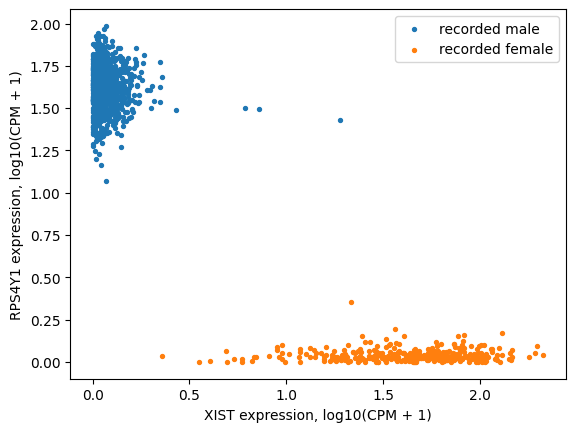

In [7]:
import numpy as np
import matplotlib.pyplot as plt

gene_names = counts["Description"]
raw = counts.drop(columns="Description")
cpm = raw / raw.sum() * 1e6

brain = brain.set_index("SAMPID")
brain["XIST"] = cpm[gene_names == "XIST"].iloc[0]
brain["RPS4Y1"] = cpm[gene_names == "RPS4Y1"].iloc[0]

for sex, color in [("male", "tab:blue"), ("female", "tab:orange")]:
    d = brain[brain["sex"] == sex]
    plt.scatter(np.log10(d["XIST"] + 1), np.log10(d["RPS4Y1"] + 1), s=8, c=color, label=f"recorded {sex}")
plt.xlabel("XIST expression, log10(CPM + 1)")
plt.ylabel("RPS4Y1 expression, log10(CPM + 1)")
plt.legend()
plt.show()

In [19]:
brain = pd.read_csv("brain_samples.csv").set_index("SAMPID")
brain["XIST"] = cpm.loc[gene_names == "XIST"].iloc[0]
brain["RPS4Y1"] = cpm.loc[gene_names == "RPS4Y1"].iloc[0]
brain["log_XIST"] = np.log10(brain["XIST"] + 1)
brain["log_RPS4Y1"] = np.log10(brain["RPS4Y1"] + 1)

ambiguous = ((brain["sex"] == "male") & (brain["log_XIST"] > 0.5)) | \
            ((brain["sex"] == "female") & (brain["log_RPS4Y1"] > 0.5))
flagged = brain.loc[ambiguous, "SUBJID"].unique()
print(brain.loc[ambiguous, ["SUBJID", "region", "log_XIST", "log_RPS4Y1"]])

# Other regions from the same donors: if XIST is low there, the issue is one sample, not the person
print(brain[brain["SUBJID"].isin(flagged)][["SUBJID", "region", "log_XIST"]].sort_values("SUBJID"))

brain = brain[~ambiguous]
counts = pd.concat([gene_names, raw[brain.index]], axis=1)
print(counts.shape)
print(pd.crosstab(brain["region"], brain["sex"], margins=True))

                                   SUBJID              region  log_XIST  \
SAMPID                                                                    
GTEX-16XZZ-0011-R3a-SM-7IGLH   GTEX-16XZZ  anterior_cingulate  0.784102   
GTEX-16Z82-0011-R6a-SM-7IGLV   GTEX-16Z82   nucleus_accumbens  1.278599   
GTEX-1EH9U-0011-R10a-SM-CJI2A  GTEX-1EH9U      frontal_cortex  0.856065   

                               log_RPS4Y1  
SAMPID                                     
GTEX-16XZZ-0011-R3a-SM-7IGLH     1.501155  
GTEX-16Z82-0011-R6a-SM-7IGLV     1.429991  
GTEX-1EH9U-0011-R10a-SM-CJI2A    1.496306  
                                   SUBJID              region  log_XIST
SAMPID                                                                 
GTEX-16XZZ-0011-R10b-SM-7LT91  GTEX-16XZZ      frontal_cortex  0.022687
GTEX-16XZZ-0011-R3a-SM-7IGLH   GTEX-16XZZ  anterior_cingulate  0.784102
GTEX-16XZZ-0011-R6a-SM-7IGNE   GTEX-16XZZ   nucleus_accumbens  0.045525
GTEX-16XZZ-0011-R7b-SM-7MGVT   GTEX-16XZZ   

In [22]:
genes = pd.read_csv(DATA + "ensembl_genes.tsv", sep="\t")
genes = genes.rename(columns={
    "Gene stable ID": "gene_id", "Gene name": "gene_name",
    "Chromosome/scaffold name": "chrom", "Gene start (bp)": "start",
    "Gene end (bp)": "end", "Gene % GC content": "gc", "Gene type": "biotype"})
genes["length"] = genes["end"] - genes["start"] + 1
genes = genes.drop_duplicates("gene_id").set_index("gene_id")
print(genes[["gene_name", "chrom", "length", "gc", "biotype"]].head())

counts = counts[~counts.index.str.endswith("_PAR_Y")]
counts.index = counts.index.str.split(".").str[0]
print("duplicate IDs:", counts.index.duplicated().sum())

chrom = genes["chrom"].reindex(counts.index)
print(chrom.isna().sum(), "genes not found in current Ensembl")
drop = (chrom == "Y") | (counts["Description"] == "XIST")
counts = counts[~drop]
print(drop.sum(), "Y-chromosome/XIST genes removed; remaining:", counts.shape)

                gene_name chrom  length     gc  biotype
gene_id                                                
ENSG00000210049     MT-TF    MT      71  40.85  Mt_tRNA
ENSG00000211459   MT-RNR1    MT     954  45.49  Mt_rRNA
ENSG00000210077     MT-TV    MT      69  42.03  Mt_tRNA
ENSG00000210082   MT-RNR2    MT    1559  42.81  Mt_rRNA
ENSG00000209082    MT-TL1    MT      75  38.67  Mt_tRNA
duplicate IDs: 0
76 genes not found in current Ensembl
653 Y-chromosome/XIST genes removed; remaining: (73975, 1339)


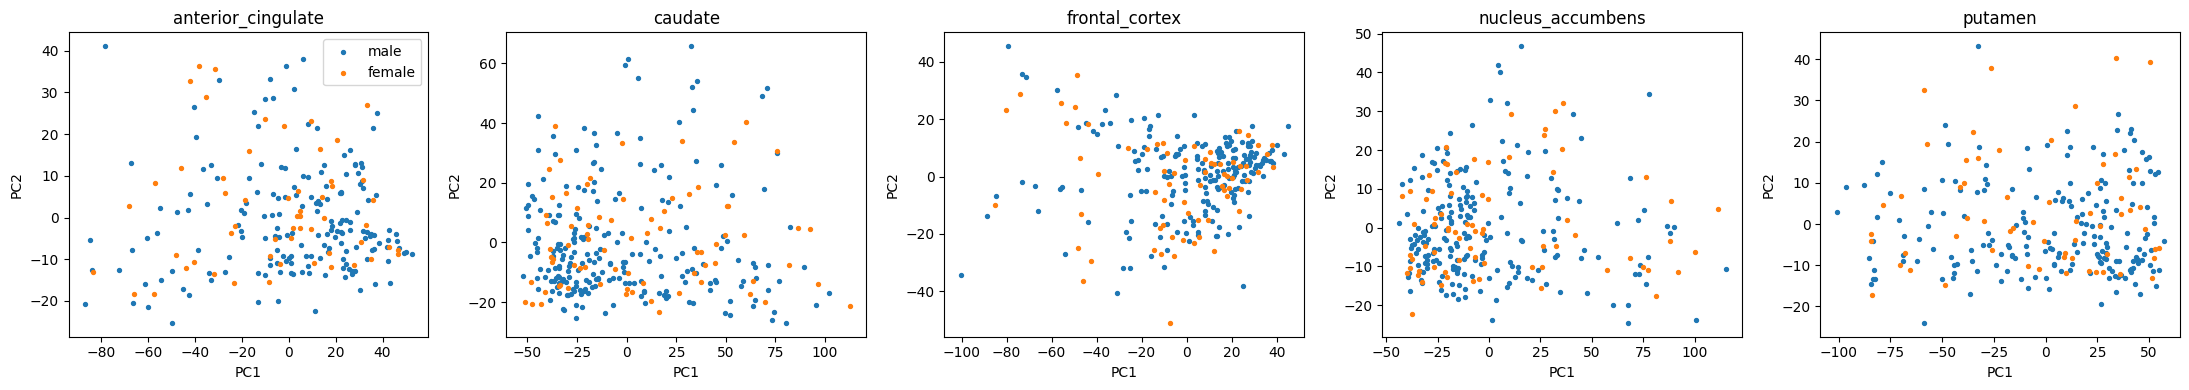

Outlier samples (>4 SD on PC1 or PC2): []


In [23]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
outliers = []
for ax, (region, info) in zip(axes, brain.groupby("region")):
    c = counts[info.index]
    logcpm = np.log2(c / c.sum() * 1e6 + 1)
    logcpm = logcpm[logcpm.mean(axis=1) > 1]
    top = logcpm.loc[logcpm.var(axis=1).nlargest(2000).index].values
    centered = top - top.mean(axis=1, keepdims=True)
    U, S, Vt = np.linalg.svd(centered, full_matrices=False)
    pcs = pd.DataFrame(Vt[:2].T * S[:2], index=info.index, columns=["PC1", "PC2"])
    z = (pcs - pcs.mean()) / pcs.std()
    outliers += list(pcs.index[(z.abs() > 4).any(axis=1)])
    for sex, color in [("male", "tab:blue"), ("female", "tab:orange")]:
        d = pcs[info["sex"] == sex]
        ax.scatter(d["PC1"], d["PC2"], s=8, c=color, label=sex)
    ax.set_title(region); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
axes[0].legend()
plt.tight_layout(); plt.show()
print("Outlier samples (>4 SD on PC1 or PC2):", outliers)

In [24]:
import os
os.makedirs("region_data", exist_ok=True)

brain_ok = brain.drop(index=outliers, errors="ignore")
print("Samples removed as PCA outliers:", len(brain) - len(brain_ok))

for region, info in brain_ok.groupby("region"):
    c = counts[info.index]
    n_min = info["sex"].value_counts().min()
    keep = (c >= 10).sum(axis=1) >= n_min
    c = c[keep]
    c.to_csv(f"region_data/{region}_counts.csv")
    info[["sex", "AGE", "SMRIN", "SMTSISCH"]].to_csv(f"region_data/{region}_samples.csv")
    print(f"{region}: {c.shape[0]} genes kept, {c.shape[1]} samples ({n_min} in smaller sex group)")

counts["Description"].to_csv("region_data/gene_names.csv")
genes.to_csv("region_data/gene_annotation.csv")

Samples removed as PCA outliers: 0
anterior_cingulate: 25168 genes kept, 232 samples (56 in smaller sex group)
caudate: 25415 genes kept, 300 samples (76 in smaller sex group)
frontal_cortex: 25280 genes kept, 268 samples (68 in smaller sex group)
nucleus_accumbens: 25634 genes kept, 284 samples (73 in smaller sex group)
putamen: 24748 genes kept, 254 samples (61 in smaller sex group)
